# 5. Re-forecasting after cleaning

Question: does removing the agreed anomalies from the **training** data improve the forecast?

Protocol
1. Anomalies come from notebook 04 (flagged by at least two methods).
2. Only the training set is cleaned. The test set is left untouched so the comparison is fair.
3. The same models and settings as notebook 03 are refitted: ARIMA(2,0,2), ARIMA(3,0,0), Prophet (additive) and Prophet (regularized).
4. Scenarios: raw, cleaned with STL imputation, cleaned with linear interpolation, and a more aggressive cleaning (any method).

AIC/BIC are computed on different data in each scenario, so they are **not comparable across scenarios**; they are shown for completeness only. RMSE and MAE on the same untouched test set are the fair comparison.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))
os.chdir(project_root)

from src.anomalies import (
    combine_flags,
    impute_anomalies,
    isolation_forest_anomalies,
    sarima_residual_anomalies,
    stl_residual_anomalies,
)
from src.eda import impute_linear
from src.forecasting import evaluate_models
from src.load_data import get_train_test, load_daily_series
from src.plots import save_current_figure

DATA_PATH = project_root / "data/processed/pm25_paris_daily.csv"
(project_root / "reports/tables").mkdir(parents=True, exist_ok=True)

series = impute_linear(load_daily_series(DATA_PATH))
train, test = get_train_test(series)
print(f"Train {train.index[0].date()} -> {train.index[-1].date()} ({len(train)} days), "
      f"test {test.index[0].date()} -> {test.index[-1].date()} ({len(test)} days)")

Importing plotly failed. Interactive plots will not work.


Train 2023-01-01 -> 2025-08-01 (944 days), test 2025-08-02 -> 2025-10-30 (90 days)


## Agreed anomaly imputation

Detection is re-run here with the same code and settings as notebook 04 so this notebook is self-contained.

Agreed anomalies in train: 15 (1.6%); in test (left untouched): 0
Any-method flags in train: 52 (5.5%)


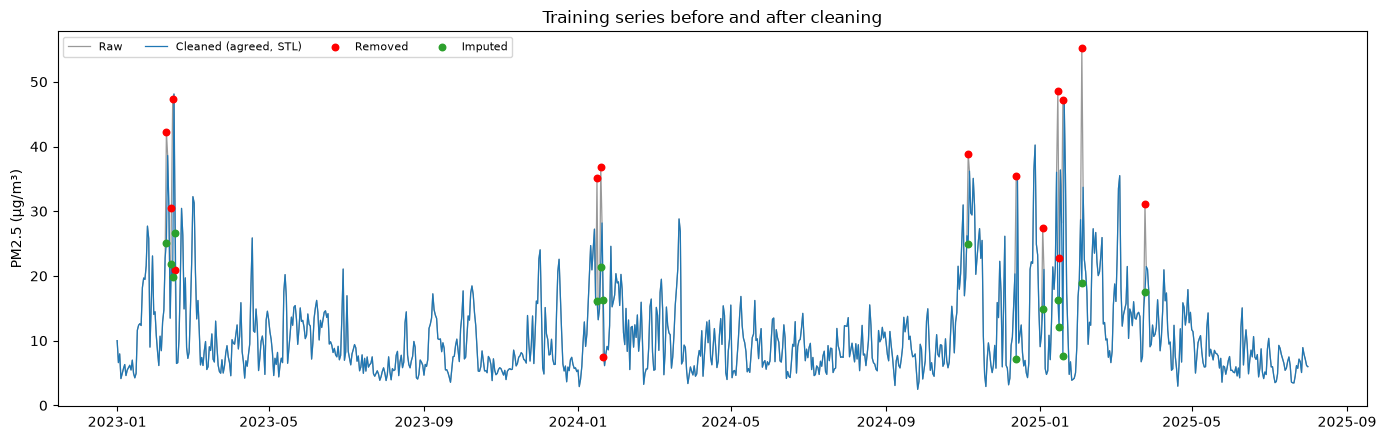

In [2]:
stl_flags, _ = stl_residual_anomalies(series)
sarima_flags = sarima_residual_anomalies(train, series, order=(2, 0, 2))
iforest = isolation_forest_anomalies(series, contamination=0.03, random_state=42)
flags = combine_flags(
    {"stl": stl_flags["is_anomaly"], "sarima": sarima_flags["is_anomaly"], "iforest": iforest["is_anomaly"]},
    series.index,
)

agreed = flags["n_methods"] >= 2
any_flag = flags["n_methods"] >= 1
train_agreed = agreed.loc[train.index]
train_any = any_flag.loc[train.index]
print(f"Agreed anomalies in train: {int(train_agreed.sum())} ({train_agreed.mean():.1%}); "
      f"in test (left untouched): {int(agreed.loc[test.index].sum())}")
print(f"Any-method flags in train: {int(train_any.sum())} ({train_any.mean():.1%})")

scenarios = {
    "Raw (before)": train,
    "Cleaned: agreed, STL imputation": impute_anomalies(train, train_agreed, method="stl"),
    "Cleaned: agreed, linear imputation": impute_anomalies(train, train_agreed, method="linear"),
    "Cleaned: any method, STL imputation": impute_anomalies(train, train_any, method="stl"),
}

changed = scenarios["Cleaned: agreed, STL imputation"]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(train.index, train.values, color="0.6", linewidth=0.9, label="Raw")
ax.plot(changed.index, changed.values, color="tab:blue", linewidth=0.9, label="Cleaned (agreed, STL)")
ax.scatter(train[train_agreed].index, train[train_agreed].values, color="red", s=22, label="Removed", zorder=3)
ax.scatter(changed[train_agreed].index, changed[train_agreed].values, color="tab:green", s=22,
           label="Imputed", zorder=3)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Training series before and after cleaning")
ax.legend(ncol=4, fontsize=8)
fig.tight_layout()
save_current_figure("05_cleaning_effect.png")
plt.show()

## Refit SARIMA and Prophet

Each scenario refits the four models on its own training series and scores them on the same raw test period.

In [3]:
frames = []
for name, tr in scenarios.items():
    result = evaluate_models(tr, test)
    result.insert(0, "scenario", name)
    frames.append(result)
    print(f"done: {name}")
all_results = pd.concat(frames).reset_index()
all_results.round(3).to_csv("reports/tables/05_reforecast_all_scenarios.csv", index=False)

18:40:27 - cmdstanpy - INFO - Chain [1] start processing


18:40:27 - cmdstanpy - INFO - Chain [1] done processing


done: Raw (before)


done: Cleaned: agreed, STL imputation


done: Cleaned: agreed, linear imputation


done: Cleaned: any method, STL imputation


## Before vs after comparison

,RMSE before,RMSE after,RMSE change %,MAE before,MAE after,MAE change %,AIC before,AIC after,BIC before,BIC after
model,,,,,,,,,,
"ARIMA(2,0,2)",4.185,4.716,12.706,3.621,4.204,16.097,5598.713,5552.501,5627.814,5581.602
"ARIMA(3,0,0)",4.894,4.725,-3.449,4.367,4.219,-3.388,5602.515,5551.638,5626.765,5575.888
Prophet (additive),4.239,4.153,-2.027,3.426,3.421,-0.135,NaN,NaN,NaN,NaN
Prophet (regularized),3.781,3.811,0.778,2.941,3.040,3.379,NaN,NaN,NaN,NaN


scenario,Raw (before),"Cleaned: agreed, STL imputation","Cleaned: agreed, linear imputation","Cleaned: any method, STL imputation"
model,,,,
"ARIMA(2,0,2)",4.185,4.716,4.140,4.184
"ARIMA(3,0,0)",4.894,4.725,4.812,4.549
Prophet (additive),4.239,4.153,4.198,4.115
Prophet (regularized),3.781,3.811,3.795,3.835


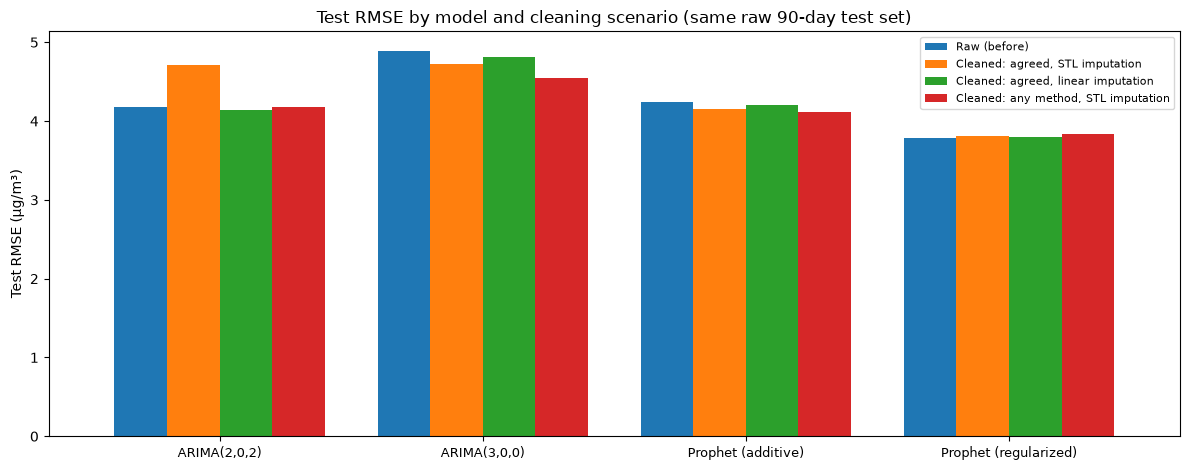

In [4]:
before = all_results[all_results["scenario"] == "Raw (before)"].set_index("model")
after = all_results[all_results["scenario"] == "Cleaned: agreed, STL imputation"].set_index("model")

comparison = pd.DataFrame(
    {
        "RMSE before": before["RMSE"],
        "RMSE after": after["RMSE"],
        "RMSE change %": (after["RMSE"] / before["RMSE"] - 1) * 100,
        "MAE before": before["MAE"],
        "MAE after": after["MAE"],
        "MAE change %": (after["MAE"] / before["MAE"] - 1) * 100,
        "AIC before": before["AIC"],
        "AIC after": after["AIC"],
        "BIC before": before["BIC"],
        "BIC after": after["BIC"],
    }
).round(3)
display(comparison)
comparison.to_csv("reports/tables/05_before_after.csv")

pivot = all_results.pivot(index="model", columns="scenario", values="RMSE")[list(scenarios)]
display(pivot.round(3))
ax = pivot.plot(kind="bar", figsize=(12, 4.8), width=0.8)
ax.set_ylabel("Test RMSE (µg/m³)")
ax.set_xlabel("")
ax.set_title("Test RMSE by model and cleaning scenario (same raw 90-day test set)")
plt.xticks(rotation=0, fontsize=9)
ax.legend(fontsize=8)
ax.figure.tight_layout()
save_current_figure("05_before_after_rmse.png")
plt.show()

## Conclusion

In [5]:
best_before = before["RMSE"].idxmin()
best_after = after["RMSE"].idxmin()
improved = (after["RMSE"] < before["RMSE"]).sum()
worst_change = comparison["RMSE change %"].abs().max()
print(f"Best model before cleaning: {best_before} (RMSE {before['RMSE'].min():.3f})")
print(f"Best model after cleaning:  {best_after} (RMSE {after['RMSE'].min():.3f})")
print(f"Models with lower RMSE after cleaning: {improved} / {len(comparison)}")
print(f"Largest absolute RMSE change: {worst_change:.1f}%")

Best model before cleaning: Prophet (regularized) (RMSE 3.781)
Best model after cleaning:  Prophet (regularized) (RMSE 3.811)
Models with lower RMSE after cleaning: 2 / 4
Largest absolute RMSE change: 12.7%


**Written conclusion**

- **Cleaning did not improve the forecast consistently.** With the main configuration (agreed anomalies, STL imputation), test RMSE falls for ARIMA(3,0,0) (-3.4%) and Prophet additive (-2.0%), but rises for ARIMA(2,0,2) (+12.7%) and Prophet regularized (+0.8%). The best model is Prophet (regularized) both before (RMSE 3.78) and after (3.81).
- **Why the effect is small.** The 90-day test window (Aug to Oct 2025) is a calm season with no agreed anomalies, and long-horizon ARIMA forecasts converge to the series mean within about two weeks. Cleaning mostly shifts that mean and the variance estimate rather than the dynamics, so the effect on RMSE is a level shift of a fraction of a µg/m³ that can go either way.
- **AIC/BIC dropping after cleaning is expected and not evidence of a better forecast**: the cleaned series simply has fewer extreme values to explain, and the likelihoods are computed on different data.
- **The imputation choice matters about as much as the cleaning itself.** Linear interpolation is slightly better than STL imputation for ARIMA(2,0,2) (4.14 vs 4.72), and cleaning any single-method flag (more aggressive) helps ARIMA(3,0,0) most (4.55) but does not beat Prophet regularized.
- **Recommendation.** Keep the anomalies in the data for forecasting calm periods; cleaning is worthwhile when the forecast window follows an episode or when anomaly-sensitive intervals matter. A single 90-day window is too short to separate a real effect from noise; a rolling-origin evaluation with cleaning inside each fold would be the next step.